# 2. Filtros e divisão dos dados

**Pergunta deste notebook:** quais músicas entram no experimento, e como separar treino, validação e teste sem que o modelo "cole"?

Partimos de 24.077 músicas extraídas de 8.367 jogos. Nem todas servem, e a divisão exige cuidado porque jogos de PICO-8 copiam música uns dos outros.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbkit as k

k.estilo()
stats = k.ler_json(k.ARTEFATOS / "dados" / "build_stats.json")
print(f"entrada: {stats['songs_in']:,} músicas de {stats['games_in']:,} jogos".replace(",", "."))
print(f"mantidas: {stats['kept']:,}".replace(",", "."))

entrada: 24.077 músicas de 8.367 jogos
mantidas: 12.384


## O funil

Cada filtro tira músicas por um motivo específico:

| Filtro | O que tira | Por quê |
|---|---|---|
| poucas notas | músicas com menos de 16 notas | são efeitos sonoros e vinhetas, não música |
| instrumentos customizados | músicas que usam um SFX como instrumento | o vocabulário e o sintetizador só cobrem os 8 instrumentos padrão |
| velocidades incompatíveis | canais com velocidades que não fecham no mesmo pattern | não cabem numa grade comum de tempo |
| duplicadas | cópias exatas de uma música já vista | a mesma música aparece em vários jogos; sem isso, o teste repetiria o treino |

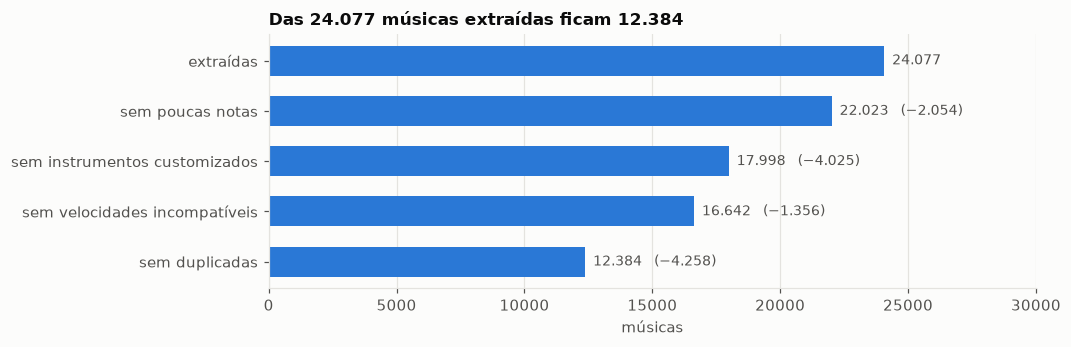

In [2]:
rotulos = {"few_notes": "poucas notas", "custom_instruments": "instrumentos customizados",
           "incompatible_speeds": "velocidades incompatíveis", "duplicate": "duplicadas"}
restam, etapas = stats["songs_in"], [("extraídas", stats["songs_in"], 0)]
for chave, rotulo in rotulos.items():
    restam -= stats["dropped"][chave]
    etapas.append((f"sem {rotulo}", restam, stats["dropped"][chave]))

fig, ax = plt.subplots(figsize=(9, 3))
nomes = [e[0] for e in etapas]
ax.barh(nomes, [e[1] for e in etapas], color=k.AZUL, height=0.6)
for i, (_, fica, sai) in enumerate(etapas):
    texto = f"{fica:,}".replace(",", ".") + (f"   (−{sai:,})".replace(",", ".") if sai else "")
    ax.text(fica + 300, i, texto, va="center", fontsize=9, color=k.TINTA2)
ax.invert_yaxis(); ax.set_xlim(0, 30000); ax.set_xlabel("músicas"); ax.grid(axis="y", visible=False)
ax.set_title("Das 24.077 músicas extraídas ficam 12.384", loc="left")
plt.show()

## O problema do vazamento

Se uma música do teste for igual (ou quase igual) a uma do treino, o modelo acerta por memória e as métricas ficam otimistas. No PICO-8 isso acontece muito: jogos reaproveitam SFX e músicas inteiras.

Opções que consideramos:

1. **Dividir por música.** Simples, mas duas músicas do mesmo jogo, que compartilham trechos, cairiam em lados diferentes.
2. **Dividir por jogo.** Melhor, mas jogos diferentes também compartilham trechos: nessa divisão, 34,6% das músicas de teste eram idênticas a músicas de treino.
3. **Dividir por grupo de jogos (a escolhida).** Jogos que compartilham algum trecho ficam no mesmo grupo, e o grupo inteiro vai para um lado só.

Os grupos saem assim: cada jogo é um ponto; dois jogos que compartilham um trecho (bloco com 4 notas ou mais) são ligados; cada conjunto de jogos ligados é um grupo.

In [3]:
print(f"{stats['groups']:,} grupos".replace(",", "."))
k.tabela([{"grupo": g["group"], "músicas": g["songs"], "jogos": g["games"], "foi para": g["split"]}
          for g in stats["largest_groups"]])

5.237 grupos


| grupo | músicas | jogos | foi para |
|---|---|---|---|
| 1810 | 545 | 230 | train |
| 2518 | 298 | 111 | train |
| 144041 | 32 | 3 | train |
| 53014 | 27 | 1 | test |
| 30189 | 23 | 4 | train |

Dois grupos são enormes (545 e 298 músicas): são trechos muito copiados entre jogos. Um grupo desse tamanho distorceria a validação ou o teste, então os grupos com mais de 1% das músicas vão sempre para o treino. Os demais são sorteados (semente 831) até fechar 70/15/15.

## A divisão final

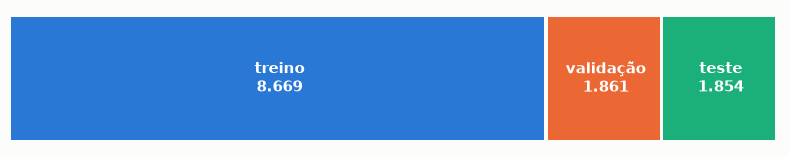

    treino:  8669 músicas (70%) de 4092 jogos
 validação:  1861 músicas (15%) de 894 jogos
     teste:  1854 músicas (15%) de 873 jogos


In [4]:
sp = stats["splits"]
nomes = {"train": "treino", "val": "validação", "test": "teste"}
fig, ax = plt.subplots(figsize=(9, 1.6))
inicio = 0
for chave, cor in zip(nomes, [k.AZUL, k.LARANJA, k.VERDE]):
    n = sp[chave]["songs"]
    ax.barh([0], [n - 60], left=inicio, color=cor, height=0.6)
    ax.text(inicio + n / 2, 0, f"{nomes[chave]}\n{n:,}".replace(",", "."),
            ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    inicio += n
ax.set_xlim(0, stats["kept"]); ax.axis("off")
plt.show()
for chave in nomes:
    print(f"{nomes[chave]:>10}: {sp[chave]['songs']:>5} músicas ({100 * sp[chave]['songs'] / stats['kept']:.0f}%) de {sp[chave]['games']} jogos")

Para que serve cada parte:

- **Treino:** as músicas que o modelo vê para ajustar os pesos.
- **Validação:** usada durante o treino para escolher a melhor época e os hiperparâmetros.
- **Teste:** usada uma vez, no fim, para os números do artigo.

A divisão fica congelada em `data/splits/split_manifest.csv`, e todo mundo do grupo usa a mesma.

## Conferindo no arquivo de teste

In [5]:
teste = k.musicas_reais()
print(f"{len(teste)} músicas de {len({m['tid'] for m in teste})} jogos no teste")

1854 músicas de 873 jogos no teste


## O que levar daqui

- Metade das músicas extraídas sai nos filtros; o filtro que mais pesa é o de duplicadas.
- A divisão é por grupos de jogos que compartilham trechos, para o teste medir generalização e não memória.
- A divisão é 70/15/15 e está congelada.

**Experimente:** conte quantas músicas tem o jogo com mais músicas no teste (`collections.Counter(m['tid'] for m in teste).most_common(3)`).

Anterior: [1. O PICO-8 e o dataset](01_pico8_e_o_dataset.ipynb) · Próximo: [3. Tokenização](03_tokenizacao.ipynb).